# 30 Doradus Hα distributions

This notebook compares the current bin-0 Hα samples:

- `MUSE-30Dor-H-bin0.fits`
- `SAMFP-30Dor-Ha-bin0.fits`

The FITS `MASK` extension is applied consistently to `MOM0`, `MOM1`, and `MOM2` before any statistics or distributions are computed.


In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import seaborn as sns
from astropy.io import fits
from matplotlib import pyplot as plt

# --------------------------------------------------
# Paths
# --------------------------------------------------
ROOT = Path.cwd()
FITS_DIR = ROOT / "fits_files"
FIGS_DIR = ROOT / "Imgs"
FIGS_DIR.mkdir(exist_ok=True)


In [2]:
# --------------------------------------------------
# Current samples
# --------------------------------------------------

datasets = [
    {
        "instrument": "MUSE",
        "line": "H",
        "filename": "MUSE-30Dor-H-bin0.fits",
        "label": r"H$\alpha$",
    },
    {
        "instrument": "SAMFP",
        "line": "H",
        "filename": "SAMFP-30Dor-Ha-bin0.fits",
        "label": r"H$\alpha$",
    },
]

INSTRUMENT_ORDER = ("MUSE", "SAMFP")

instrument_colors = {
    "MUSE": "darkgray",
    "SAMFP": "black",
}


## Load the FITS maps

`MASK=True` is interpreted as a valid pixel, following the convention used in the previous notebook. The mask is applied to all available moments before flattening the maps.


In [3]:
def load_moment_dataset(entry, fits_dir=FITS_DIR):
    fits_path = fits_dir / entry["filename"]

    with fits.open(fits_path) as hdul:
        mom0 = hdul["MOM0"].data.astype(float)
        mom1 = hdul["MOM1"].data.astype(float)
        mask = hdul["MASK"].data.astype(bool)

        # MOM2 is expected in the current workflow, but keep the
        # loader tolerant in case an older file does not contain it.
        if "MOM2" in hdul:
            mom2 = hdul["MOM2"].data.astype(float)
        else:
            mom2 = np.full_like(mom1, np.nan, dtype=float)

    # --------------------------------------------------
    # Apply the same mask to every moment
    # --------------------------------------------------
    mom0 = np.where(mask, mom0, np.nan)
    mom1 = np.where(mask, mom1, np.nan)
    mom2 = np.where(mask, mom2, np.nan)

    yy, xx = np.indices(mom1.shape)

    df = pd.DataFrame({
        "X": xx.ravel(),
        "Y": yy.ravel(),
        "SB": mom0.ravel(),
        "VV": mom1.ravel(),
        "SIGMA": mom2.ravel(),
        "mask": mask.ravel(),
    })

    # Retain only pixels admitted by the FITS mask.
    df = df[df["mask"]].copy()

    df["instrument"] = entry["instrument"]
    df["line"] = entry["line"]
    df["label"] = entry["label"]
    df["filename"] = entry["filename"]

    # --------------------------------------------------
    # Centered radial velocity
    # --------------------------------------------------
    mean_v = df["VV"].mean(skipna=True)
    df["RV_centered"] = df["VV"] - mean_v

    # --------------------------------------------------
    # Brightness quantities
    # --------------------------------------------------
    # Positive MOM0 values are required for logarithms.
    positive_sb = df["SB"].where(df["SB"] > 0)

    median_sb = positive_sb.median(skipna=True)

    df["log_SB"] = np.log10(positive_sb)

    if np.isfinite(median_sb) and median_sb > 0:
        df["SB_norm"] = positive_sb / median_sb
        df["log_SB_norm"] = np.log10(df["SB_norm"])
    else:
        df["SB_norm"] = np.nan
        df["log_SB_norm"] = np.nan

    raw = {
        "mom0": mom0,
        "mom1": mom1,
        "mom2": mom2,
        "mask": mask,
        "instrument": entry["instrument"],
        "line": entry["line"],
        "label": entry["label"],
        "filename": entry["filename"],
    }

    return df, raw


In [4]:
processed_list = []
raw_data = {}

for entry in datasets:
    df, raw = load_moment_dataset(entry)
    processed_list.append(df)
    raw_data[entry["instrument"]] = raw

processed_data = pd.concat(
    processed_list,
    ignore_index=True,
)

processed_data.head()


,X,Y,SB,VV,SIGMA,mask,instrument,line,label,filename,RV_centered,log_SB,SB_norm,log_SB_norm
0,306,0,0.131409,271.013497,NaN,True,MUSE,H,H$\alpha$,MUSE-30Dor-H-bin0.fits,5.454857,-0.881374,1.658424,0.219696
1,307,0,0.126746,273.394009,NaN,True,MUSE,H,H$\alpha$,MUSE-30Dor-H-bin0.fits,7.835369,-0.897066,1.599573,0.204004
2,308,0,0.108470,276.240517,NaN,True,MUSE,H,H$\alpha$,MUSE-30Dor-H-bin0.fits,10.681878,-0.964692,1.368918,0.136378
3,309,0,0.104170,273.005903,NaN,True,MUSE,H,H$\alpha$,MUSE-30Dor-H-bin0.fits,7.447263,-0.982257,1.314658,0.118813
4,310,0,0.095146,272.423073,NaN,True,MUSE,H,H$\alpha$,MUSE-30Dor-H-bin0.fits,6.864434,-1.021612,1.200765,0.079458


In [5]:
# --------------------------------------------------
# Quick sample summary
# --------------------------------------------------

summary = (
    processed_data
    .groupby("instrument")
    .agg(
        n_pixels=("mask", "size"),
        mean_velocity=("VV", "mean"),
        sigma_velocity=("RV_centered", "std"),
        median_brightness=("SB", "median"),
    )
)

display(summary)


,n_pixels,mean_velocity,sigma_velocity,median_brightness
instrument,,,,
MUSE,363045,265.558639,15.879360,0.079237
SAMFP,476129,275.662302,17.992844,0.055399


## Velocity histogram and brightness PDF

The left panel shows the PDF of the centered radial velocity. The right panel shows the PDF of the Hα brightness after normalizing each sample by its own median positive `MOM0` value. This normalization is useful for comparing the *shape* of the brightness distributions when the two instruments may not share the same absolute flux calibration.


In [11]:
def _auto_symmetric_xlim(values, percentile=99.5):
    values = np.asarray(values, dtype=float)
    values = values[np.isfinite(values)]

    if values.size == 0:
        return (-1.0, 1.0)

    limit = np.nanpercentile(
        np.abs(values),
        percentile,
    )

    if not np.isfinite(limit) or limit <= 0:
        limit = np.nanmax(
            np.abs(values)
        )

    if not np.isfinite(limit) or limit <= 0:
        limit = 1.0

    return (-limit, limit)


def plot_velocity_brightness_distributions(
    data,
    instrument_order=INSTRUMENT_ORDER,
    velocity_binwidth=1.0,
    brightness_bins=40,
    velocity_xlim=None,
    brightness_xlim=None,
    log_y=False,
    savepath=None,
):

    fig, axes = plt.subplots(
        1, 2,
        figsize=(12, 4.8),
    )

    ax_i, ax_v = axes

    # --------------------------------------------------
    # Velocity PDF
    # --------------------------------------------------
    for instrument in instrument_order:

        inst_df = data[
            data["instrument"] == instrument
        ]

        if inst_df.empty:
            continue

        # Original radial velocity statistics
        vv = inst_df["VV"].to_numpy(dtype=float)
        vv = vv[np.isfinite(vv)]

        mean_v = np.nanmean(vv)
        sigma_v = np.nanstd(
            vv,
            ddof=1,
        )

        velocity_label = (
            rf"{instrument}: "
            rf"$\langle V\rangle={mean_v:.1f}$, "
            rf"$\sigma={sigma_v:.1f}$ km s$^{{-1}}$"
        )

        sns.histplot(
            data=inst_df,
            x="RV_centered",
            binwidth=velocity_binwidth,
            element="step",
            fill=False,
            stat="density",
            common_norm=False,
            color=instrument_colors.get(
                instrument
            ),
            label=velocity_label,
            ax=ax_v,
        )

    if velocity_xlim is None:
        velocity_xlim = _auto_symmetric_xlim(
            data["RV_centered"].to_numpy(),
            percentile=99.5,
        )

    ax_v.set_xlim(
        *velocity_xlim
    )

    ax_v.set_xlabel(
        r"Radial velocity relative to mean "
        r"[km s$^{-1}$]"
    )

    ax_v.set_ylabel(
        "Probability density"
    )

    ax_v.set_title(
        r"H$\alpha$ velocity"
    )

    ax_v.legend(
        frameon=False,
        fontsize=9,
    )

    ax_v.grid(
        alpha=0.25
    )

    # --------------------------------------------------
    # Brightness PDF
    # --------------------------------------------------
    for instrument in instrument_order:

        inst_df = data[
            data["instrument"] == instrument
        ]

        if inst_df.empty:
            continue

        # Statistics of plotted brightness quantity
        brightness = (
            inst_df["log_SB_norm"]
            .to_numpy(dtype=float)
        )

        brightness = brightness[
            np.isfinite(brightness)
        ]

        mean_i = np.nanmean(
            brightness
        )

        sigma_i = np.nanstd(
            brightness,
            ddof=1,
        )

        brightness_label = (
            rf"{instrument}: "
            rf"$\mu={mean_i:.2f}$, "
            rf"$\sigma={sigma_i:.2f}$"
        )

        sns.histplot(
            data=inst_df,
            x="log_SB_norm",
            bins=brightness_bins,
            element="step",
            fill=False,
            stat="density",
            common_norm=False,
            color=instrument_colors.get(
                instrument
            ),
            label=brightness_label,
            ax=ax_i,
        )

    if brightness_xlim is not None:
        ax_i.set_xlim(
            *brightness_xlim
        )

    ax_i.set_xlabel(
        r"$\log_{10}[I / \mathrm{median}(I)]$"
    )

    ax_i.set_ylabel(
        "Probability density"
    )

    ax_i.set_title(
        r"H$\alpha$ brightness"
    )

    ax_i.legend(
        frameon=False,
        fontsize=9,
    )

    ax_i.grid(
        alpha=0.25
    )

    # --------------------------------------------------
    # Logarithmic y-axis
    # --------------------------------------------------
    if log_y:
        ax_v.set_yscale(
            "log"
        )

        ax_i.set_yscale(
            "log"
        )

    # --------------------------------------------------
    # Figure title
    # --------------------------------------------------
    fig.suptitle(
        r"30 Doradus — H$\alpha$",
        fontsize=15,
    )

    fig.tight_layout()

    # --------------------------------------------------
    # Save
    # --------------------------------------------------
    if savepath is not None:
        fig.savefig(
            savepath,
            dpi=300,
            bbox_inches="tight",
        )

    plt.show()

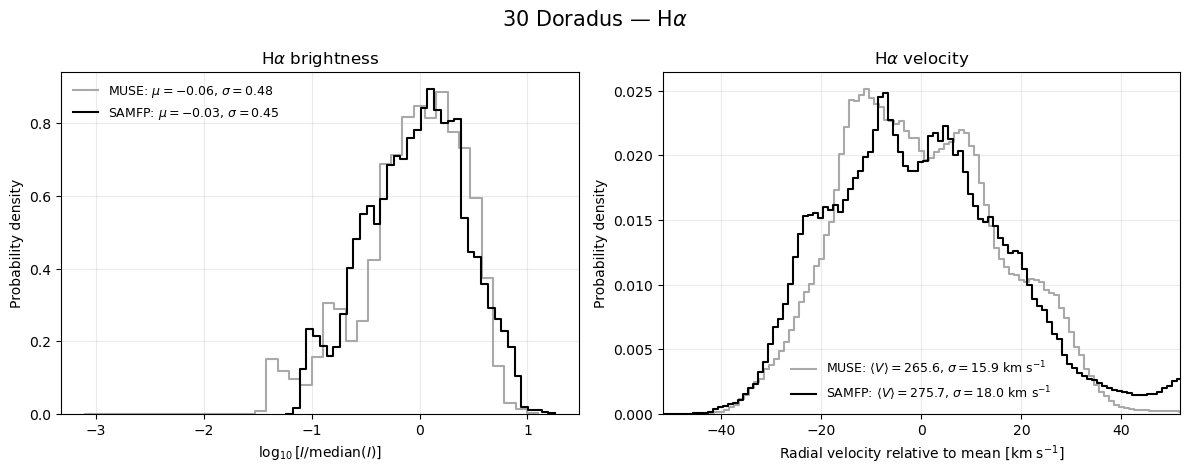

In [12]:
# --------------------------------------------------
# Linear-density version
# --------------------------------------------------

plot_velocity_brightness_distributions(
    processed_data,
    velocity_binwidth=1.0,
    brightness_bins=40,
    log_y=False,
    savepath=(
        FIGS_DIR
        / "velocity_brightness_distributions.pdf"
    ),
)


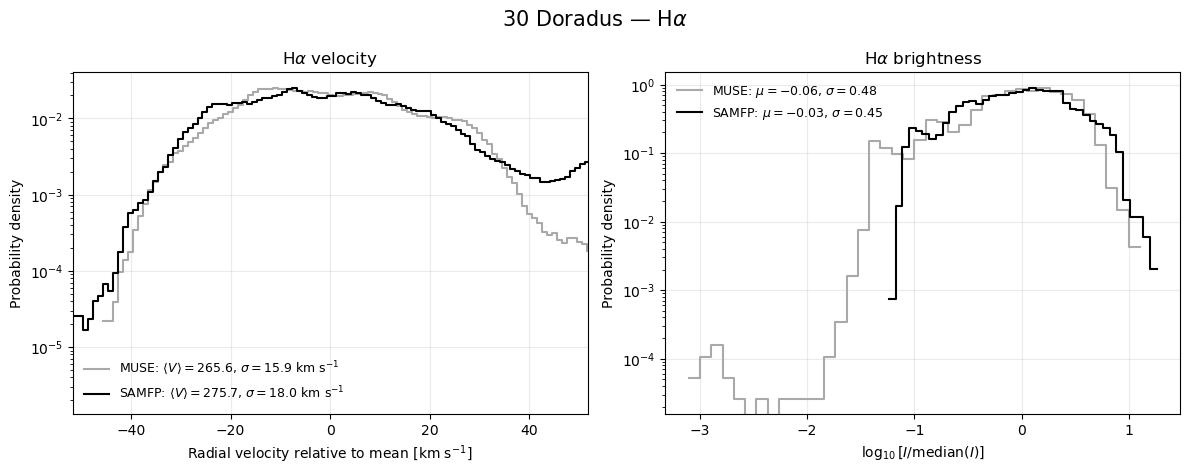

In [10]:
# --------------------------------------------------
# Optional log-density version
# --------------------------------------------------

plot_velocity_brightness_distributions(
    processed_data,
    velocity_binwidth=1.0,
    brightness_bins=40,
    log_y=True,
    savepath=(
        FIGS_DIR
        / "velocity_brightness_distributions_log.pdf"
    ),
)


## Optional: absolute brightness PDFs

If MUSE and SAMFP are confirmed to use compatible `MOM0` units/calibration, the following plot compares the native brightness distributions rather than median-normalized brightness.


In [9]:
def plot_absolute_brightness_pdf(
    data,
    instrument_order=INSTRUMENT_ORDER,
    bins=40,
    xlim=None,
    log_y=False,
    savepath=None,
):
    fig, ax = plt.subplots(figsize=(7, 5))

    for instrument in instrument_order:
        inst_df = data[data["instrument"] == instrument]

        if inst_df.empty:
            continue

        sns.histplot(
            data=inst_df,
            x="log_SB",
            bins=bins,
            element="step",
            fill=False,
            stat="density",
            common_norm=False,
            color=instrument_colors.get(instrument),
            label=instrument,
            ax=ax,
        )

    if xlim is not None:
        ax.set_xlim(*xlim)

    if log_y:
        ax.set_yscale("log")

    ax.set_xlabel(r"$\log_{10}(I)$")
    ax.set_ylabel("Probability density")
    ax.set_title(r"30 Doradus — H$\alpha$ brightness PDF")
    ax.legend(frameon=False)
    ax.grid(alpha=0.25)

    fig.tight_layout()

    if savepath is not None:
        fig.savefig(
            savepath,
            dpi=300,
            bbox_inches="tight",
        )

    plt.show()
